In [1]:
import pandas as pd

In [27]:
df=pd.read_excel('https://github.com/datagy/mediumdata/raw/master/sample_pivot.xlsx',parse_dates=['Date'])
df

,Date,Region,Type,Units,Sales
0,2020-07-11,East,Children's Clothing,18.0,306
1,2020-09-23,North,Children's Clothing,14.0,448
2,2020-04-02,South,Women's Clothing,17.0,425
3,2020-02-28,East,Children's Clothing,26.0,832
4,2020-03-19,West,Women's Clothing,3.0,33
...,...,...,...,...,...
995,2020-02-11,East,Children's Clothing,35.0,735
996,2020-12-25,North,Men's Clothing,NaN,1155
997,2020-08-31,South,Men's Clothing,13.0,208
998,2020-08-23,South,Women's Clothing,17.0,493


Creating a Pivot Table in Pandas

In [3]:
import numpy as np

In [4]:
df.groupby('Region')[['Sales','Units']].agg(np.mean)

,Sales,Units
Region,,
East,408.182482,19.732360
North,438.924051,19.202643
South,432.956204,20.423358
West,452.029412,19.294118


In [5]:
pivot=pd.pivot_table(data=df, index='Region', values=['Sales','Units']) #by default mean
pivot

,Sales,Units
Region,,
East,408.182482,19.732360
North,438.924051,19.202643
South,432.956204,20.423358
West,452.029412,19.294118


In [ ]:
pivot=pd.pivot_table(data=df, index='Region', values=['Sales','Units'], aggfunc='sum') 
pivot

,Sales,Units
Region,,
East,167763,8110.0
North,138700,4359.0
South,59315,2798.0
West,61476,2624.0


In [ ]:
pivot=pd.pivot_table(data=df, index='Region', values=['Sales','Units'], aggfunc=['mean','sum']) 
pivot

mean                sum        
             Sales      Units   Sales   Units
Region                                       
East    408.182482  19.732360  167763  8110.0
North   438.924051  19.202643  138700  4359.0
South   432.956204  20.423358   59315  2798.0
West    452.029412  19.294118   61476  2624.0

Specifying Different Aggregations Per Column

In [8]:
pivot=pd.pivot_table(data=df, index='Region', aggfunc={'Sales':'mean', 'Units':'sum'}) 
pivot

,Sales,Units
Region,,
East,408.182482,8110.0
North,438.924051,4359.0
South,432.956204,2798.0
West,452.029412,2624.0


Custom Aggregations in Pandas Pivot Tables

In [9]:
def mean_no_outliers(val):
    no_outliers=val.quantile([0.1,0.9])
    mean=np.mean(no_outliers)
    return mean

In [10]:
pivot=pd.pivot_table(data=df, index='Region', values='Sales', aggfunc=['mean',mean_no_outliers]) 
pivot

,mean,mean_no_outliers
,Sales,Sales
Region,,
East,408.182482,436.0
North,438.924051,484.5
South,432.956204,434.1
West,452.029412,497.0


In [11]:
data = {
    'Unemployment_Rate': [6.1, 5.8, 5.7, 5.7, 5.8, 5.6, 5.5, 5.3, 5.2, 5.2], 
    'Stock_Index_Price': [1500, 1520, 1525, 1523, 1515, 1540, 1545, 1560, 1555, 1565] 
}
df = pd.DataFrame(data, columns=['Unemployment_Rate', 
'Stock_Index_Price']) 
print(df) 

   Unemployment_Rate  Stock_Index_Price
0                6.1               1500
1                5.8               1520
2                5.7               1525
3                5.7               1523
4                5.8               1515
5                5.6               1540
6                5.5               1545
7                5.3               1560
8                5.2               1555
9                5.2               1565


<Axes: xlabel='Unemployment_Rate', ylabel='Stock_Index_Price'>

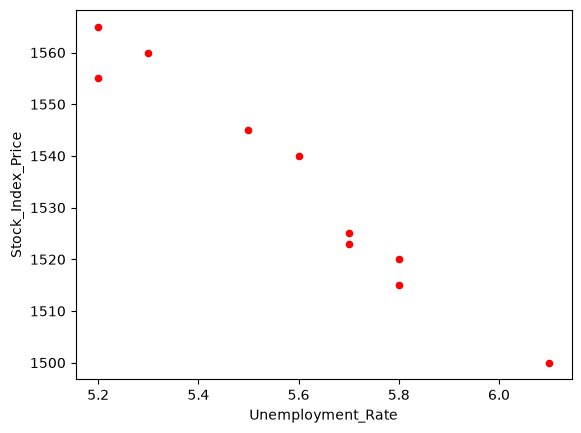

In [13]:
df.plot(x='Unemployment_Rate', y='Stock_Index_Price', kind='scatter', color='r')

In [19]:
data = {
    'Year': [1920,1930,1940,1950,1960,1970,1980,1990,2000,2010], 
    'Unemployment_Rate': [9.8,12,8,7.2,6.9,7,6.5,6.2,5.5,6.3] 
} 
df = pd.DataFrame(data) 
print(df) 

   Year  Unemployment_Rate
0  1920                9.8
1  1930               12.0
2  1940                8.0
3  1950                7.2
4  1960                6.9
5  1970                7.0
6  1980                6.5
7  1990                6.2
8  2000                5.5
9  2010                6.3


<Axes: xlabel='Year'>

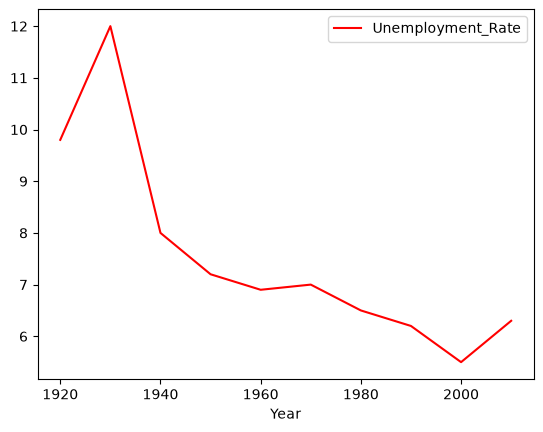

In [20]:
df.plot(x='Year', y='Unemployment_Rate', kind='line', color='r')

<Axes: xlabel='Country'>

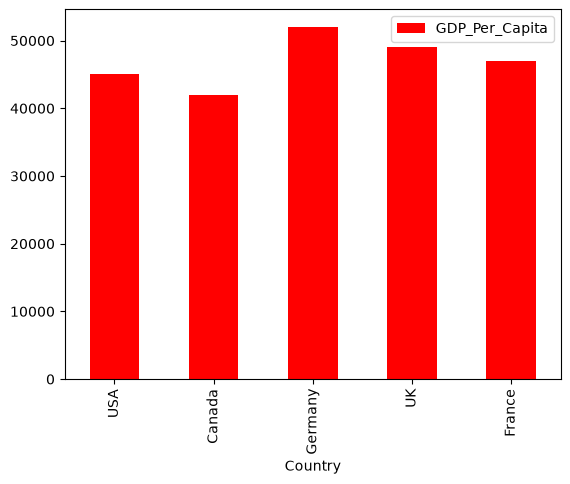

In [23]:
data = {
    'Country': ['USA','Canada','Germany','UK','France'], 
    'GDP_Per_Capita': [45000,42000,52000,49000,47000] 
} 
df = pd.DataFrame(data,columns=['Country','GDP_Per_Capita']) 
df.plot(x ='Country', y='GDP_Per_Capita', kind = 'bar', color='r') 


In [5]:
import numpy as np
def mean_no_outliers(val):
    no_outliers=val.quantile([0.1,0.9])
    mean=np.mean(no_outliers)
    return mean

In [6]:
pivot=pd.pivot_table(data=df, index='Region', values='Sales', aggfunc=['mean',mean_no_outliers]) 
pivot

,mean,mean_no_outliers
,Sales,Sales
Region,,
East,408.182482,436.0
North,438.924051,484.5
South,432.956204,434.1
West,452.029412,497.0


In [10]:
pivot=pd.pivot_table(data=df, index='Region', columns='Type', values='Sales')
pivot

Type,Children's Clothing,Men's Clothing,Women's Clothing
Region,,,
East,405.743363,423.647541,399.028409
North,438.894118,449.157303,432.528169
South,412.666667,475.435897,418.924528
West,480.523810,465.292683,419.188679


In [15]:
pivot.loc[['East','North'],"Men's Clothing"]

Region
East     423.647541
North    449.157303
Name: Men's Clothing, dtype: float64

In [8]:
df

,Date,Region,Type,Units,Sales
0,2020-07-11,East,Children's Clothing,18.0,306
1,2020-09-23,North,Children's Clothing,14.0,448
2,2020-04-02,South,Women's Clothing,17.0,425
3,2020-02-28,East,Children's Clothing,26.0,832
4,2020-03-19,West,Women's Clothing,3.0,33
...,...,...,...,...,...
995,2020-02-11,East,Children's Clothing,35.0,735
996,2020-12-25,North,Men's Clothing,NaN,1155
997,2020-08-31,South,Men's Clothing,13.0,208
998,2020-08-23,South,Women's Clothing,17.0,493


In [16]:
pivot=pd.pivot_table(data=df, index=['Region',df['Date'].dt.quarter], columns='Type', values='Sales')
pivot

Type         Children's Clothing  Men's Clothing  Women's Clothing
Region Date                                                       
East   1              423.241379      369.250000        428.948718
       2              274.800000      445.425000        456.816327
       3              425.382353      506.421053        342.386364
       4              453.866667      405.666667        364.795455
North  1              394.727273      450.869565        489.944444
       2              461.791667      478.916667        406.263158
       3              443.806452      482.947368        432.850000
       4              427.526316      388.478261        393.892857
South  1              509.400000      433.214286        465.785714
       2              376.363636      482.875000        463.687500
       3              430.909091      460.875000        370.937500
       4              353.538462      547.444444        332.571429
West   1              484.266667      532.307692        401.333333
       2              523.444444      394.571429        308.090909
       3              316.857143      406.285714        542.083333
       4              544.454545      467.928571        417.055556

In [17]:
pivot.loc[('East',1),"Men's Clothing"]

np.float64(369.25)

Customizing Pandas Pivot Tables

In [18]:
pivot=pd.pivot_table(data=df, index='Region', columns='Type', values='Sales', margins=True)
pivot

Type,Children's Clothing,Men's Clothing,Women's Clothing,All
Region,,,,
East,405.743363,423.647541,399.028409,408.182482
North,438.894118,449.157303,432.528169,438.924051
South,412.666667,475.435897,418.924528,432.956204
West,480.523810,465.292683,419.188679,452.029412
All,427.743860,444.257732,415.254717,427.254000


In [22]:
pivot=pd.pivot_table(data=df, index='Region', columns='Type', values='Sales', margins=True, margins_name='Total')
pivot

Type,Children's Clothing,Men's Clothing,Women's Clothing,Total
Region,,,,
East,405.743363,423.647541,399.028409,408.182482
North,438.894118,449.157303,432.528169,438.924051
South,412.666667,475.435897,418.924528,432.956204
West,480.523810,465.292683,419.188679,452.029412
Total,427.743860,444.257732,415.254717,427.254000


In [24]:
df.loc[(df['Region']=='East') & (df['Type']=="Children's Clothing"), 'Sales']=np.nan
pivot=pd.pivot_table(data=df, index='Region', columns='Type', values='Sales')
pivot

Type,Children's Clothing,Men's Clothing,Women's Clothing
Region,,,
East,NaN,423.647541,399.028409
North,438.894118,449.157303,432.528169
South,412.666667,475.435897,418.924528
West,480.523810,465.292683,419.188679


In [25]:
pivot=pd.pivot_table(data=df, index='Region', columns='Type', values='Sales', fill_value=0)
pivot

Type,Children's Clothing,Men's Clothing,Women's Clothing
Region,,,
East,0.000000,423.647541,399.028409
North,438.894118,449.157303,432.528169
South,412.666667,475.435897,418.924528
West,480.523810,465.292683,419.188679


Sorting Pandas Pivot Table Data

In [28]:
df

,Date,Region,Type,Units,Sales
0,2020-07-11,East,Children's Clothing,18.0,306
1,2020-09-23,North,Children's Clothing,14.0,448
2,2020-04-02,South,Women's Clothing,17.0,425
3,2020-02-28,East,Children's Clothing,26.0,832
4,2020-03-19,West,Women's Clothing,3.0,33
...,...,...,...,...,...
995,2020-02-11,East,Children's Clothing,35.0,735
996,2020-12-25,North,Men's Clothing,NaN,1155
997,2020-08-31,South,Men's Clothing,13.0,208
998,2020-08-23,South,Women's Clothing,17.0,493


In [32]:
pivot=pd.pivot_table(data=df, index=['Region',df['Date'].dt.quarter], values='Sales', sort=True)
pivot

Sales
Region Date            
East   1     406.692308
       2     419.238532
       3     403.608247
       4     402.178218
North  1     462.142857
       2     442.034884
       3     447.200000
       4     401.242857
South  1     465.263158
       2     440.628571
       3     410.342857
       4     408.655172
West   1     475.000000
       2     402.296296
       3     444.884615
       4     466.209302

In [33]:
print(pivot[pivot['Sales']>pivot['Sales'].mean()])

                  Sales
Region Date            
North  1     462.142857
       2     442.034884
       3     447.200000
South  1     465.263158
       2     440.628571
West   1     475.000000
       3     444.884615
       4     466.209302
